# 과제 B — OCR로 표 이미지를 다시 쓰기 · Colab 실행/테스트 노트북
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/crystalmoon74/AIImage-assignments/blob/main/ocr/paddleocr_colab.ipynb)

저장소: https://github.com/crystalmoon74/AIImage-assignments

| 부 | 내용 | 시간(CPU) |
|---|---|---|
| 0 | 준비: 저장소 받기 + 패키지 설치 | 약 1분 |
| 1 | **과제 B 재현** — Census 1910 Table 1 → CSV·document.md, 합계 검사, 사람 검토 반영 | 약 1분 |
| 2 | 테스트 이미지 2장(FRASER No.11, Census 세계표)에 같은 OCR 적용 | 약 1분 |
| 3 | **내 이미지로 테스트** — 파일 업로드 또는 URL, '확인 필요' 기준 조정 | 이미지당 수십 초 |
| 4 | (선택) 원본 PaddleOCR 엔진으로 같은 표 실행 → 1부 결과와 핵심 칸 비교 | 3~5분 |
| 5 | 결과 zip 다운로드 | - |

**사용법:** 메뉴 `런타임 → 모두 실행`. 3부에서 파일 선택 창이 뜨면 표 이미지를 고르세요(건너뛰려면 `취소`). GPU는 필요 없습니다(CPU 런타임 기준).

> 1~3부의 엔진은 로컬 결과와 같은 **RapidOCR + ONNX Runtime**(PaddleOCR PP-OCRv5 가중치의 ONNX 변환본)입니다. 로컬 PC는 Windows 스마트 앱 컨트롤이 paddlepaddle DLL을 막아 원본 엔진을 쓸 수 없었기 때문에, 원본 PaddleOCR 엔진은 4부에서 따로 실행해 비교합니다.

## 0. 준비

In [ ]:
import os, sys, json, glob, shutil, subprocess
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    if not os.path.exists('/content/AIImage-assignments'):
        !git clone -q --depth 1 https://github.com/crystalmoon74/AIImage-assignments.git /content/AIImage-assignments
    os.chdir('/content/AIImage-assignments')
    # 로컬과 같은 버전 고정. 실패하면(파이썬 버전 차이 등) 최신 버전으로 대신 설치 — 이 경우 결과가 달라질 수 있음
    !pip -q install rapidocr==3.10.0 onnxruntime==1.31.1 || pip -q install rapidocr onnxruntime
else:  # 로컬에서 이 노트북을 실행하는 경우(.venv-ocr): ocr/ 폴더에서 저장소 루트로 이동
    if os.path.basename(os.getcwd()) == 'ocr':
        os.chdir('..')
print('작업 폴더:', os.getcwd(), '| Colab:', IN_COLAB, '| Python', sys.version.split()[0])

import pandas as pd
from IPython.display import Image, Markdown, display

def sh(*args):
    """저장소 스크립트를 현재 파이썬으로 실행하고 출력을 보여 준다."""
    r = subprocess.run([sys.executable, *args], capture_output=True, text=True)
    print(r.stdout[-4000:], r.stderr[-4000:] if r.returncode else '')
    return r.returncode

def show_quick(out_dir, n_lines=25):
    """ocr_quick.py 결과 보기: 영역 그림(빨강=확인 필요), 확인 필요 목록, 줄 단위 텍스트."""
    raw = json.load(open(f'{out_dir}/raw_ocr.json', encoding='utf-8'))
    items = raw['items']
    flagged = [it for it in items if it['needs_review']]
    print(f"영역 {len(items)}개 / 확인 필요 {len(flagged)}개 (점수 기준 {raw.get('score_review_threshold')})")
    display(Image(f'{out_dir}/ocr_regions.png', width=900))
    if flagged:
        display(pd.DataFrame([{'id': it['id'], 'text': it['text'], 'score': it['score'],
                               'bbox_xyxy': it['bbox_xyxy'], '이유': ', '.join(it['needs_review'])}
                              for it in flagged]))
    lines = open(f'{out_dir}/lines.txt', encoding='utf-8').read().splitlines()
    print(f'--- 줄 단위 텍스트 (앞 {n_lines}줄 / 전체 {len(lines)}줄, (?) = 확인 필요) ---')
    print('\n'.join(lines[:n_lines]))

## 1. 과제 B 재현 — Census 1910 Table 1
`ocr/run_ocr.py` 를 **수정 없이** 실행합니다. 결과는 `outputs/ocr_colab/` 에 저장되어, 저장소에 커밋된 로컬 결과 `outputs/ocr/` 와 바로 대조할 수 있습니다.

- 사람 검토 기록 `ocr/review/corrections.json` 은 OCR 원시값이 기록과 같을 때만 적용됩니다. Colab에서 원시값이 달라지면 스크립트가 **멈추고 어느 칸이 다른지** 알려 줍니다(검토 없이 고치지 않도록).

In [ ]:
rc = sh('ocr/run_ocr.py', '--out', 'outputs/ocr_colab')
assert rc == 0, '실행 실패 — 위 메시지 확인(검토 기록과 OCR 원시값이 다르면 여기서 멈춥니다)'
m = json.load(open('outputs/ocr_colab/manifest.json', encoding='utf-8'))
print('실행 위치:', m['execution_location'])
print('패키지   :', m['packages'])

### 1-1. 결과 표와 로컬 결과 대조

In [ ]:
colab = pd.read_csv('outputs/ocr_colab/table.csv')
local = pd.read_csv('outputs/ocr/table.csv')
display(colab)
print('로컬(outputs/ocr/table.csv)과 완전히 같은가:', colab.equals(local))
raw_c = pd.read_csv('outputs/ocr_colab/table_raw.csv'); raw_l = pd.read_csv('outputs/ocr/table_raw.csv')
print('검토 전 원시 표(table_raw.csv)도 같은가 :', raw_c.equals(raw_l))

### 1-2. 합계 검사 (검토 전 → 검토 후)와 사람 검토 기록

In [ ]:
rep = json.load(open('outputs/ocr_colab/review_report.json', encoding='utf-8'))
chk = pd.DataFrame(rep['raw_checks'])[['check', 'lhs', 'rhs', 'ok']].rename(columns={'ok': '검토 전'})
chk['검토 후'] = [c['ok'] for c in rep['final_checks']]
display(chk)
display(pd.DataFrame(rep['corrections'])[['ocr_id', 'where', 'expected_raw', 'corrected', 'reason']])
print('남은 확인 필요:', rep['needs_review'] or '없음')

### 1-3. 검토 표시 그림과 근거 확대 이미지
번호 표시 = 자동 '확인 필요' 후보 / 사람이 고친 칸. 확대 이미지는 원본 픽셀 그대로 잘라낸 것입니다.

In [ ]:
display(Image('outputs/ocr_colab/review_overlay.png', width=1000))
for p in sorted(glob.glob('outputs/ocr_colab/review_evidence/*.png')):
    print(os.path.basename(p)); display(Image(p))

### 1-4. 최종 문서 (document.md)

In [ ]:
display(Markdown(open('outputs/ocr_colab/document.md', encoding='utf-8').read()))

## 2. 테스트 이미지 2장
`ocr/ocr_quick.py` 는 표 복원·검토 없이 **어떤 오류가 나는지** 먼저 보는 1단계 도구입니다. 빨간 테두리 = 확인 필요(점수 < 기준, 또는 숫자 사이에 O/I/l/S 같은 글자).

- `b1-fraser-table.png`: FRASER Annual Report 1935 (No. 11 표 계열) — 촘촘한 숫자, 점선 리더
- `b2-census-world-table.png`: Census 1910 세계 인구표 — 끝자리 0 누락 사례

In [ ]:
sh('ocr/ocr_quick.py', 'input/test/b1-fraser-table.png', 'input/test/b2-census-world-table.png',
   '--out', 'outputs/ocr_test_colab')
for stem in ('b1-fraser-table', 'b2-census-world-table'):
    display(Markdown(f'### {stem}')); show_quick(f'outputs/ocr_test_colab/{stem}')

## 3. 내 이미지로 테스트
- `IMAGE_URL` 에 이미지 주소를 넣으면 그 이미지를, 비워 두면 **파일 업로드 창**이 뜹니다(여러 장 가능).
- `SCORE_REVIEW`: 이 점수 미만의 인식 결과를 '확인 필요'로 표시합니다. 과제 기본값 0.90.
- 결과: `outputs/ocr_user/<파일명>/` (raw_ocr.json, ocr_regions.png, lines.txt)
- **공유 조건:** 저작권·개인정보가 있는 문서는 올리지 마세요. 업로드 파일은 이 Colab 런타임에만 저장되고 저장소에는 올라가지 않습니다.

b2-census-world-table.png: 영역 105개, 확인 필요 후보 23개 → outputs/ocr_user/b2-census-world-table
    23 '443,520,000' 0.8179 ['score<0.9']
    24 "8 '9" 0.7205 ['score<0.9']
    25 '8 9' 0.7798 ['score<0.9']
    37 '3, 457,000' 0.7187 ['score<0.9']
    38 '7,467,00' 0.8815 ['score<0.9']
    41 '4,892,00' 0.7365 ['score<0.9']
    42 '1,000' 0.8053 ['score<0.9']
    44 '(3)' 0.8811 ['score<0.9']
    53 '418,253, 000' 0.8724 ['score<0.9']
    58 '162, 439,, 00' 0.8383 ['score<0.9']
    68 '92,081,000' 0.788 ['score<0.9']
    70 'Aa$' 0.5039 ['score<0.9']
    73 '77,313,,00' 0.8494 ['score<0.9']
    77 '25,000' 0.6966 ['score<0.9']
    79 "9'0" 0.6807 ['score<0.9']
 


### b2-census-world-table.png

영역 105개 / 확인 필요 23개 (점수 기준 0.9)


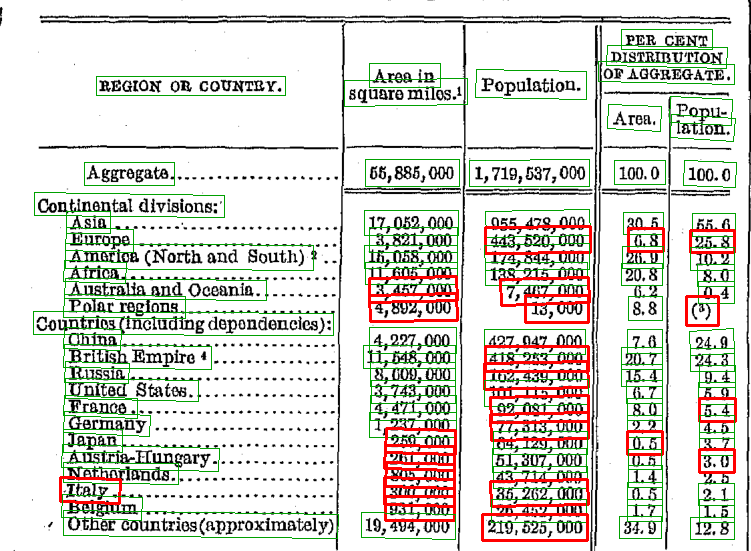

,id,text,score,bbox_xyxy,이유
0,23,"443,520,000",0.8179,"[485.0, 226.0, 590.0, 253.0]",score<0.9
1,24,8 '9,0.7205,"[628.0, 228.0, 663.0, 251.0]",score<0.9
2,25,8 9,0.7798,"[690.0, 230.0, 734.0, 252.0]",score<0.9
3,37,"3, 457,000",0.7187,"[369.0, 276.0, 457.0, 302.0]",score<0.9
4,38,"7,467,00",0.8815,"[500.0, 277.0, 589.0, 305.0]",score<0.9
5,41,"4,892,00",0.7365,"[369.0, 293.0, 457.0, 321.0]",score<0.9
6,42,"1,000",0.8053,"[525.0, 295.0, 588.0, 322.0]",score<0.9
7,44,(3),0.8811,"[686.0, 296.0, 718.0, 325.0]",score<0.9
8,53,"418,253, 000",0.8724,"[485.0, 346.0, 588.0, 371.0]",score<0.9
9,58,"162, 439,, 00",0.8383,"[484.0, 361.0, 588.0, 389.0]",score<0.9


--- 줄 단위 텍스트 (앞 25줄 / 전체 27줄, (?) = 확인 필요) ---
PER CENT
DISTRIBUTION
Area in | OF AGGREGATE.
REGION OR COUNTRY. | square milos.1 | Population.
Area. | Popu-
ltion.
Aggregate. | 55,885,000 | 1,719,537,000 | 100.0 | 100.0
Continental divisions:'
Asia | 17,052,000 | 955, 478,000 | 30. 5 | 55.6
Europe | 3,821,000 | 443,520,000(?) | 8 '9(?) | 8 9(?)
Amerioa (North and South) | 15,058,000 | 174,844,000 | 26.9 | 10.2
Africa. | 11,605,000 | 138,215,000 | 20.8 | 8.0
Australia and Oceania.. | 3, 457,000(?) | 7,467,00(?) | 0.4
Polar regions, | 4,892,00(?) | 1,000(?) | 8.8 | (3)(?)
Countrios (including depondencies):
China | 4,227,000 | 427,047,000 | 7.6 | 24.9
British Empire  | 11,548,000 | 418,253, 000(?) | 20.7 | 24.3
Russia | 8,609,000 | 162, 439,, 00(?) | 15.4 | 6
United States. | 3,743,000 | 101, 115, 000 | 6.7 | 5.9
France. | 4,471,000 | 92,081,000(?) | 8.0 | Aa$(?)
Germany | 1,237,00 | 77,313,,00(?) | 2.2 | 4.5
Japan | 25,000(?) | 64,129, 000 | 9'0(?) | 3.7
Austria-Fungary. | 261 000(?) | 

In [24]:
SCORE_REVIEW = 0.9  #@param {type:"slider", min:0.5, max:1.0, step:0.01}
IMAGE_URL = "https://raw.githubusercontent.com/crystalmoon74/AIImage-assignments/main/input/test/b2-census-world-table.png"  #@param {type:"string"}
os.makedirs('input/user', exist_ok=True)
user_files = []
if IMAGE_URL.strip():
    import urllib.request, urllib.parse
    name = os.path.basename(urllib.parse.urlparse(IMAGE_URL).path) or 'url_image.png'
    dst = os.path.join('input/user', name)
    req = urllib.request.Request(IMAGE_URL, headers={'User-Agent': 'Mozilla/5.0 (ocr-test-notebook)'})
    open(dst, 'wb').write(urllib.request.urlopen(req, timeout=60).read())
    user_files.append(dst)
elif IN_COLAB:
    from google.colab import files
    try:
        for name, data in files.upload().items():
            dst = os.path.join('input/user', os.path.basename(name))
            open(dst, 'wb').write(data); user_files.append(dst)
    except Exception as e:
        print('업로드 건너뜀:', e)
if not user_files:
    print('입력 이미지가 없어 3부를 건너뜁니다. 이 셀을 다시 실행해 업로드하거나 IMAGE_URL을 넣으세요.')
else:
    sh('ocr/ocr_quick.py', *user_files, '--score', str(SCORE_REVIEW), '--out', 'outputs/ocr_user')
    for f in user_files:
        stem = os.path.splitext(os.path.basename(f))[0]
        if os.path.exists(f'outputs/ocr_user/{stem}/raw_ocr.json'):
            display(Markdown(f'### {os.path.basename(f)}')); show_quick(f'outputs/ocr_user/{stem}')

**결과 읽는 법:** 점수가 높아도 틀릴 수 있습니다(예: 1부의 `17, 635, 426` 은 점수 0.996이지만 위첨자 ¹ 이 붙은 오류). 그래서 숫자 표는 **원본 대조 + 합계 같은 산술 검사**를 함께 해야 합니다. 표를 CSV로 복원하려면 1부의 `run_ocr.py` 처럼 열 경계·행 묶음 규칙을 그 표에 맞게 정해야 합니다.

## 4. (선택) 원본 PaddleOCR 엔진으로 같은 표 실행
로컬 PC에서는 실행할 수 없었던 `paddlepaddle` + `paddleocr` 로 같은 Census 표를 읽고, 1부(RapidOCR)에서 사람이 고친 핵심 칸이 어떻게 읽히는지 비교합니다. 설치에 몇 분 걸립니다.

- 모델: 1부와 같은 계열인 **PP-OCRv5_server_det + en_PP-OCRv5_mobile_rec** 를 이름으로 지정합니다. (paddleocr 3.7은 `lang='en'` 만 주면 기본값이 PP-OCRv6_medium 이라, 지정하지 않으면 엔진과 가중치가 함께 바뀌어 비교가 흐려집니다.)
- 문서 회전·왜곡 보정 끔(바른 스캔), 글자줄 방향 분류 켬 — 1부와 같게.
- `enable_mkldnn=False`: paddlepaddle 3.3.1 CPU의 oneDNN 경로에서 `NotImplementedError: ConvertPirAttribute2RuntimeAttribute not support` 오류가 나서 끔(Colab에서 확인한 오류).

In [ ]:
RUN_PADDLE = True  #@param {type:"boolean"}
if RUN_PADDLE and IN_COLAB:
    !pip -q install paddlepaddle==3.3.1 paddleocr==3.7.0
elif not IN_COLAB:
    print('로컬 실행: paddlepaddle DLL 차단 환경이라 4부는 건너뜁니다(Colab에서 실행하세요).'); RUN_PADDLE = False

In [ ]:
if RUN_PADDLE:
    import paddle, paddleocr
    from paddleocr import PaddleOCR
    print('paddlepaddle', paddle.__version__, '| paddleocr', paddleocr.__version__)
    ocr = PaddleOCR(text_detection_model_name='PP-OCRv5_server_det',
                    text_recognition_model_name='en_PP-OCRv5_mobile_rec',
                    use_doc_orientation_classify=False, use_doc_unwarping=False,
                    use_textline_orientation=True, device='cpu', enable_mkldnn=False)
    os.makedirs('outputs/ocr_paddle', exist_ok=True)
    res = ocr.predict('input/census-table.png')[0]
    res.save_to_json('outputs/ocr_paddle'); res.save_to_img('outputs/ocr_paddle')
    p_items = [{'text': t, 'score': round(float(s), 4), 'bbox_xyxy': [int(v) for v in b]}
               for t, s, b in zip(res['rec_texts'], res['rec_scores'], res['rec_boxes'])]
    print('인식 영역', len(p_items), '개')
    for img in glob.glob('outputs/ocr_paddle/*ocr_res_img*'):
        display(Image(img, width=1000))

### 4-1. 핵심 칸 비교 (1부 RapidOCR 원시값 vs PaddleOCR)
1부에서 사람이 고친 세 칸의 위치(원본 픽셀 좌표)와 가장 많이 겹치는 PaddleOCR 결과를 찾습니다.

In [ ]:
def iou(a, b):
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0])); iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    u = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - ix*iy
    return ix*iy / u if u else 0
if RUN_PADDLE:
    rapid = json.load(open('outputs/ocr_colab/raw_ocr.json', encoding='utf-8'))['items']
    rows = []
    for c in json.load(open('ocr/review/corrections.json', encoding='utf-8'))['corrections']:
        r = rapid[c['ocr_id']]
        best = max(p_items, key=lambda p: iou(p['bbox_xyxy'], r['bbox_xyxy']))
        rows.append({'칸': c['where'], '정답(원본 대조)': c['corrected'], 'RapidOCR(1부)': r['text'],
                     'PaddleOCR': best['text'], 'Paddle 점수': best['score'],
                     'Paddle 정답 일치': best['text'].replace(' ', '') == c['corrected'].replace(' ', ''),
                     '겹침 IoU': round(iou(best['bbox_xyxy'], r['bbox_xyxy']), 2)})
    display(pd.DataFrame(rows))

엔진을 바꿔도 위첨자가 숫자에 붙는 문제가 남는지/사라지는지가 비교 포인트입니다. 어느 쪽이든 **합계 검사와 원본 대조 없이 OCR 값을 그대로 쓰지 않는다**는 결론은 같습니다.

## 5. 결과 내려받기

In [ ]:
import zipfile
with zipfile.ZipFile('ocr_colab_results.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    for d in ('outputs/ocr_colab', 'outputs/ocr_test_colab', 'outputs/ocr_user', 'outputs/ocr_paddle'):
        fs = [f for f in glob.glob(d + '/**/*', recursive=True) if os.path.isfile(f)]
        for f in fs: z.write(f)
        if fs: print(d, len(fs), '개 파일')
print('ocr_colab_results.zip 생성')
if IN_COLAB:
    from google.colab import files
    files.download('ocr_colab_results.zip')